# Байесовские сети

### Представление зависимостей, оценка параметров и вероятностный вывод

На семинаре построим дискретную байесовскую сеть, проверим ее свойства и исследуем,
как структура графа и наблюдения влияют на вероятностные запросы.

Блокнот сопровождает лекцию и использует те же четыре переменные и локальные вероятности.
Основной пример является **учебной вероятностной моделью**.
Все данные далее генерируются из явно заданного распределения.

**Результат работы**

- Граф и читаемые таблицы условных вероятностей.
- Точный вывод с независимой проверкой перебором состояний.
- Последовательное добавление evidence и анализ условных независимостей.
- Оценка параметров по наблюдениям и сравнение способов сглаживания.
- Эксперимент с удалением ребра и повторной оценкой параметров.

Блокнот выполняется последовательно сверху вниз. После установки зависимостей
для выполнения не нужны внешние файлы, доступ к интернету или GPU.

## 1. Окружение и воспроизводимость

Проверено на Python 3.12. Все случайные эксперименты используют явный `seed`.
Сеть небольшая, поэтому вычисления выполняются на CPU.

Если библиотеки еще не установлены, раскомментируйте следующую ячейку и выполните ее.
После изменения зависимостей перезапустите ядро и выберите **Run All**.
В Google Colab и Jupyter команда `%pip` устанавливает пакеты в окружение текущего ядра.

In [1]:
# %pip install pgmpy==1.1.2 numpy==2.3.5 pandas==2.2.3 matplotlib==3.10.8 networkx==3.7

In [2]:
import sys
import warnings
from collections.abc import Mapping, Sequence
from importlib.metadata import version
from itertools import product

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
# Убираем только известное предупреждение о внутреннем импорте pgmpy 1.1.2.
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message=r"`pgmpy\.estimators\.StructureScore` is deprecated.*",
        category=FutureWarning,
    )
    from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE
    from pgmpy.factors.discrete import TabularCPD
    from pgmpy.inference import VariableElimination
    from pgmpy.models import DiscreteBayesianNetwork

SEED = 42
N_TRAIN = 5_000
N_TEST = 2_000
N_SENSITIVITY = 60
N_RARE = 10
ESS_VALUES = [0.1, 1, 5, 20, 100]
EQUIVALENT_SAMPLE_SIZE = 5

NODES = ("G", "S", "B", "K")
EDGES = (("G", "B"), ("S", "B"), ("B", "K"))
REDUCED_EDGES = (("G", "B"), ("B", "K"))
STATE_NAMES = {node: [0, 1] for node in NODES}

LABELS = {
    "G": "G\nДействие\nГрю",
    "S": "S\nДействие\nСтюарта",
    "B": "B\nПропажа\nбананов",
    "K": "K\nСигнал\nКевина",
}
POSITIONS = {"G": (-1, 1), "S": (1, 1), "B": (0, 0), "K": (0, -1)}
COLORS = {"main": "#2855A6", "accent": "#B9577A", "muted": "#7B818C"}

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.grid": False,
})
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 6)

software_versions = pd.Series({
    "Python": sys.version.split()[0],
    **{package: version(package) for package in
       ("pgmpy", "numpy", "pandas", "matplotlib", "networkx")},
}, name="Версия")
display(software_versions.to_frame())

,Версия
Python,3.12.14
pgmpy,1.1.2
numpy,2.3.5
pandas,2.2.3
matplotlib,3.10.8
networkx,3.7


## 2. Переменные и предположения

Один объект описывает один независимый эпизод наблюдения четырех бинарных событий.

| Переменная | Состояние 1 | Состояние 0 |
|---|---|---|
| `G` | Грю забрал бананы | Грю не забирал бананы |
| `S` | Стюарт ел бананы | Стюарт не ел бананы |
| `B` | Бананы пропали | Бананы остались |
| `K` | Кевин подал сигнал | Кевин не подал сигнал |

В нашей учебной гипотезе `G` и `S` изначально независимы.
Оба события могут объяснять `B`, а `K` зависит от `B`.
Наблюдение общего результата может сделать объясняющие его события зависимыми.

Факторизация модели

$$P(G,S,B,K)=P(G)P(S)P(B\mid G,S)P(K\mid B).$$

Направленные стрелки задают статистические ограничения.
Причинную интерпретацию рассмотрим отдельно, с дополнительными предположениями.

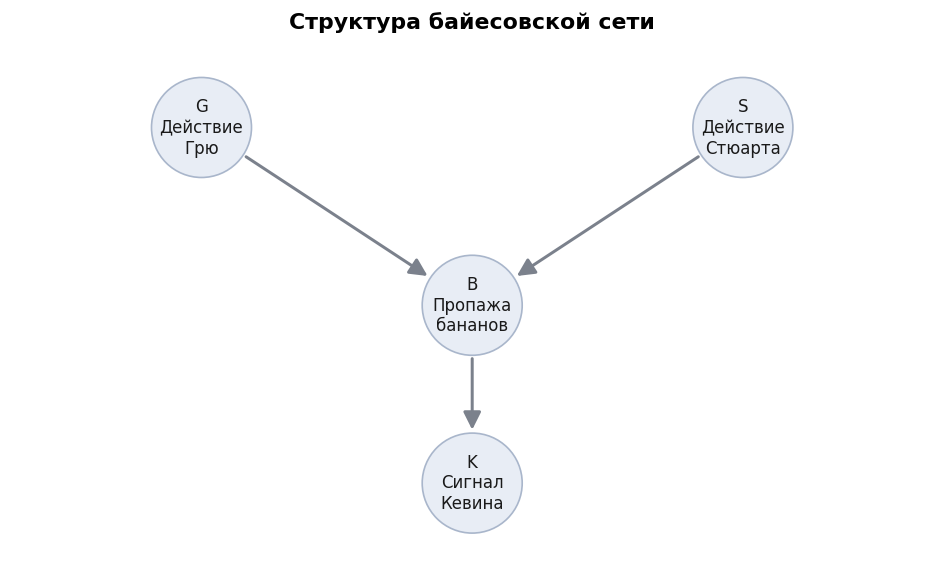

In [3]:
def draw_network(
    model: DiscreteBayesianNetwork,
    observed: Sequence[str] = (),
    title: str = "Структура байесовской сети",
) -> None:
    """Показывает фиксированную компоновку сети и выделяет наблюдаемые узлы."""
    observed = set(observed)
    unknown = observed.difference(model.nodes())
    if unknown:
        raise ValueError(f"Неизвестные наблюдаемые узлы: {sorted(unknown)}")

    fig, ax = plt.subplots(figsize=(8, 5))
    node_colors = [COLORS["main"] if node in observed else "#E8EDF5"
                   for node in model.nodes()]
    nx.draw_networkx_nodes(
        model, POSITIONS, ax=ax, node_size=3_600,
        node_color=node_colors, edgecolors="#A9B6CB", linewidths=1.0,
    )
    nx.draw_networkx_edges(
        model, POSITIONS, ax=ax, arrows=True, arrowsize=22,
        width=1.8, edge_color=COLORS["muted"],
        min_source_margin=32, min_target_margin=32,
    )
    for node, (x, y) in POSITIONS.items():
        if node in model:
            ax.text(x, y, LABELS[node], ha="center", va="center", fontsize=10,
                    color="white" if node in observed else "#1A1A1A")
    ax.set(title=title, xlim=(-1.7, 1.7), ylim=(-1.5, 1.5))
    ax.axis("off")
    fig.tight_layout()
    plt.show()

structure = DiscreteBayesianNetwork(EDGES)
structure.add_nodes_from(NODES)
assert nx.is_directed_acyclic_graph(structure)
draw_network(structure)

## 3. Явное задание локальных распределений

Узлы `G` и `S` имеют априорные распределения. Для `B` нужно четыре комбинации
состояний родителей. Для `K` достаточно двух комбинаций.

В `TabularCPD` строки соответствуют состояниям самого узла, а столбцы
комбинациям состояний родителей в указанном порядке.
В таблице `B` используем порядок `(G,S)` и комбинации `(0,0), (0,1), (1,0), (1,1)`.

Для каждого столбца сумма вероятностей равна единице.
Числа ниже согласованы с презентацией и не оценены по наблюдениям.

In [4]:
def build_reference_model() -> DiscreteBayesianNetwork:
    """Возвращает новую сеть с заданными учебными CPD."""
    model = DiscreteBayesianNetwork(EDGES)
    model.add_nodes_from(NODES)
    model.add_cpds(
        TabularCPD("G", 2, [[0.80], [0.20]], state_names={"G": [0, 1]}),
        TabularCPD("S", 2, [[0.70], [0.30]], state_names={"S": [0, 1]}),
        TabularCPD(
            "B", 2,
            [[0.99, 0.20, 0.10, 0.01],
             [0.01, 0.80, 0.90, 0.99]],
            evidence=["G", "S"], evidence_card=[2, 2],
            state_names={"B": [0, 1], "G": [0, 1], "S": [0, 1]},
        ),
        TabularCPD(
            "K", 2, [[0.95, 0.20], [0.05, 0.80]],
            evidence=["B"], evidence_card=[2],
            state_names={"K": [0, 1], "B": [0, 1]},
        ),
    )
    if not model.check_model():
        raise ValueError("Локальные распределения не согласованы с графом.")
    return model


def cpd_frame(model: DiscreteBayesianNetwork, node: str) -> pd.DataFrame:
    """Представляет CPD в таблице с явными значениями родителей."""
    cpd = model.get_cpds(node)
    parents = cpd.variables[1:]
    parent_states = [cpd.state_names[parent] for parent in parents]
    rows = []
    for combination in product(*parent_states):
        condition = dict(zip(parents, combination))
        row = condition.copy()
        for state in cpd.state_names[node]:
            assignment = {node: state, **condition}
            row[f"P({node}={state})"] = float(cpd.get_value(**assignment))
        rows.append(row)
    return pd.DataFrame(rows)


reference_model = build_reference_model()
for node in NODES:
    print(f"CPD узла {node}")
    display(cpd_frame(reference_model, node))

CPD узла G
CPD узла S
CPD узла B
CPD узла K


,P(G=0),P(G=1)
0,0.8,0.2


,P(S=0),P(S=1)
0,0.7,0.3


,G,S,P(B=0),P(B=1)
0,0,0,0.99,0.01
1,0,1,0.20,0.80
2,1,0,0.10,0.90
3,1,1,0.01,0.99


,B,P(K=0),P(K=1)
0,0,0.95,0.05
1,1,0.20,0.80


### Интерпретация CPD

- Без обоих предполагаемых объяснений вероятность `B=1` равна `0.01`.
  Модель допускает другие, явно не представленные причины.
- При `G=1, S=0` вероятность пропажи равна `0.90`.
- Сигнал Кевина несовершенен. Возможны как отсутствие сигнала при пропаже,
  так и сигнал без пропажи.

`check_model()` проверяет формальную согласованность модели.
Он не подтверждает правильность предметных предположений.

## 4. Совместное распределение и независимая проверка

Для четырех бинарных переменных существуют $2^4=16$ полных состояний.
Такую сеть удобно проверить прямым вычислением всех совместных вероятностей.

Используем факторизацию, а не алгоритм `VariableElimination`.
Позже сравним ответы двух способов на одинаковых запросах.

In [5]:
def joint_probability(
    model: DiscreteBayesianNetwork,
    assignment: Mapping[str, int],
) -> float:
    """Вычисляет вероятность полного состояния произведением локальных CPD."""
    if set(assignment) != set(model.nodes()):
        raise ValueError("Нужно задать значения всех узлов модели.")
    factors = []
    for node in model.nodes():
        cpd = model.get_cpds(node)
        local_assignment = {variable: assignment[variable]
                            for variable in cpd.variables}
        factors.append(float(cpd.get_value(**local_assignment)))
    return float(np.prod(factors))


def enumerate_joint(model: DiscreteBayesianNetwork) -> pd.DataFrame:
    """Строит совместное распределение небольшой дискретной сети."""
    nodes = list(model.nodes())
    states = [model.get_cpds(node).state_names[node] for node in nodes]
    rows = []
    for combination in product(*states):
        assignment = dict(zip(nodes, combination))
        rows.append({**assignment, "probability": joint_probability(model, assignment)})
    return pd.DataFrame(rows)


joint = enumerate_joint(reference_model)
assert np.isclose(joint["probability"].sum(), 1.0)
assert (joint["probability"] >= 0).all()
assert np.isclose(
    joint_probability(reference_model, {"G": 1, "S": 0, "B": 1, "K": 1}),
    0.1008,
)
display(joint)

,G,B,S,K,probability
0,0,0,0,0,0.52668
1,0,0,0,1,0.02772
2,0,0,1,0,0.04560
3,0,0,1,1,0.00240
4,0,1,0,0,0.00112
5,0,1,0,1,0.00448
6,0,1,1,0,0.03840
7,0,1,1,1,0.15360
8,1,0,0,0,0.01330
9,1,0,0,1,0.00070


## 5. Вероятностный запрос

Для запроса $P(Q=q\mid E=e)$ фиксируем evidence и суммируем по неизвестным переменным.

$$P(Q=q\mid E=e)=\frac{\sum_{z}P(Q=q,E=e,Z=z)}{P(E=e)}.$$

Ненаблюдаемая переменная не получает автоматически значение `0`.
Если вероятность evidence равна нулю, условная вероятность не определена.

In [6]:
def probability_by_enumeration(
    joint_distribution: pd.DataFrame,
    target: str,
    state: int = 1,
    evidence: Mapping[str, int] | None = None,
) -> float:
    """Вычисляет условную вероятность из полной совместной таблицы."""
    evidence = {} if evidence is None else dict(evidence)
    variables = set(joint_distribution.columns) - {"probability"}
    if target not in variables or set(evidence) - variables:
        raise ValueError("В запросе есть неизвестная переменная.")
    if target in evidence:
        raise ValueError("Целевая переменная не должна входить в evidence.")
    for variable, value in {target: state, **evidence}.items():
        if value not in set(joint_distribution[variable]):
            raise ValueError(f"Неизвестное состояние {variable}={value}.")

    mask = pd.Series(True, index=joint_distribution.index)
    for variable, value in evidence.items():
        mask &= joint_distribution[variable].eq(value)
    denominator = float(joint_distribution.loc[mask, "probability"].sum())
    if denominator <= 0:
        raise ValueError("Вероятность evidence равна нулю.")
    numerator = joint_distribution.loc[
        mask & joint_distribution[target].eq(state), "probability"
    ].sum()
    return float(numerator / denominator)


def probability(
    inference: VariableElimination,
    target: str,
    evidence: Mapping[str, int] | None = None,
    state: int = 1,
) -> float:
    """Возвращает вероятность заданного состояния из результата pgmpy."""
    result = inference.query(
        variables=[target], evidence={} if evidence is None else dict(evidence),
        show_progress=False,
    )
    return float(result.get_value(**{target: state}))


reference_inference = VariableElimination(reference_model)
manual = probability_by_enumeration(joint, "G", evidence={"B": 1})
pgmpy_result = probability(reference_inference, "G", {"B": 1})
assert np.isclose(manual, pgmpy_result)
print(f"Перебор состояний: {manual:.6f}")
print(f"Variable elimination: {pgmpy_result:.6f}")

Перебор состояний: 0.484073
Variable elimination: 0.484073


### Расчет одного запроса вручную

Для версии `G=1` сначала суммируем по состояниям `S`.

$$P(G=1,B=1)=0.20(0.70\cdot0.90+0.30\cdot0.99)=0.1854.$$

Аналогично

$$P(G=0,B=1)=0.80(0.70\cdot0.01+0.30\cdot0.80)=0.1976.$$

Отсюда

$$P(G=1\mid B=1)=\frac{0.1854}{0.1854+0.1976}\approx0.484073.$$

Узел `K` не наблюдаем. После суммирования по его состояниям множитель
$\sum_k P(K=k\mid B)=1$ исчезает из выражения.

## 6. Различные содержательные запросы

Проверим три вопроса с разным смыслом.

1. Какова вероятность пропажи, если известно действие Грю?
2. Какова вероятность действия Грю, если обнаружена пропажа?
3. Как меняется эта вероятность, если дополнительно известно действие Стюарта?

В таблице сравниваем ответ с априорной вероятностью того же целевого события.
Разность приводим в процентных пунктах.

In [7]:
QUERY_SPECS = [
    ("Прогноз пропажи", "B", {"G": 1}),
    ("Диагностический вывод", "G", {"B": 1}),
    ("Конкурирующее объяснение", "G", {"B": 1, "S": 1}),
]

query_rows = []
for name, target, evidence in QUERY_SPECS:
    prior = probability(reference_inference, target)
    posterior = probability(reference_inference, target, evidence)
    exhaustive = probability_by_enumeration(joint, target, evidence=evidence)
    assert np.isclose(posterior, exhaustive)
    query_rows.append({
        "Вопрос": name, "Цель": f"{target}=1", "Evidence": str(evidence),
        "До наблюдений": prior, "После наблюдений": posterior,
        "Изменение, п.п.": 100 * (posterior - prior),
    })

query_results = pd.DataFrame(query_rows)
display(query_results.round(6))
np.testing.assert_allclose(
    query_results["После наблюдений"],
    [0.927, 0.4840731070496084, 0.23627684964200474],
)

,Вопрос,Цель,Evidence,До наблюдений,После наблюдений,"Изменение, п.п."
0,Прогноз пропажи,B=1,{'G': 1},0.383,0.927000,54.400000
1,Диагностический вывод,G=1,{'B': 1},0.200,0.484073,28.407311
2,Конкурирующее объяснение,G=1,"{'B': 1, 'S': 1}",0.200,0.236277,3.627685


### Интерпретация

Действие Грю повышает вероятность пропажи. Сама пропажа, в свою очередь, повышает
вероятность действия Грю, но не делает его достоверным.
Дополнительное объяснение через `S` уменьшает необходимость объяснять результат через `G`.

Значения вычислены внутри заданной модели. Их точность как результатов алгоритма
не означает, что граф и исходные CPD точно описывают реальную предметную область.

## 7. Последовательное добавление evidence

Фиксируем целевое событие `G=1`. Сначала ничего не наблюдаем,
затем добавляем `K=1`, `B=1` и `S=1`.

,Наблюдения,P(G=1 | evidence)
0,Нет наблюдений,0.200000
1,K=1,0.441957
2,"K=1, B=1",0.484073
3,"K=1, B=1, S=1",0.236277


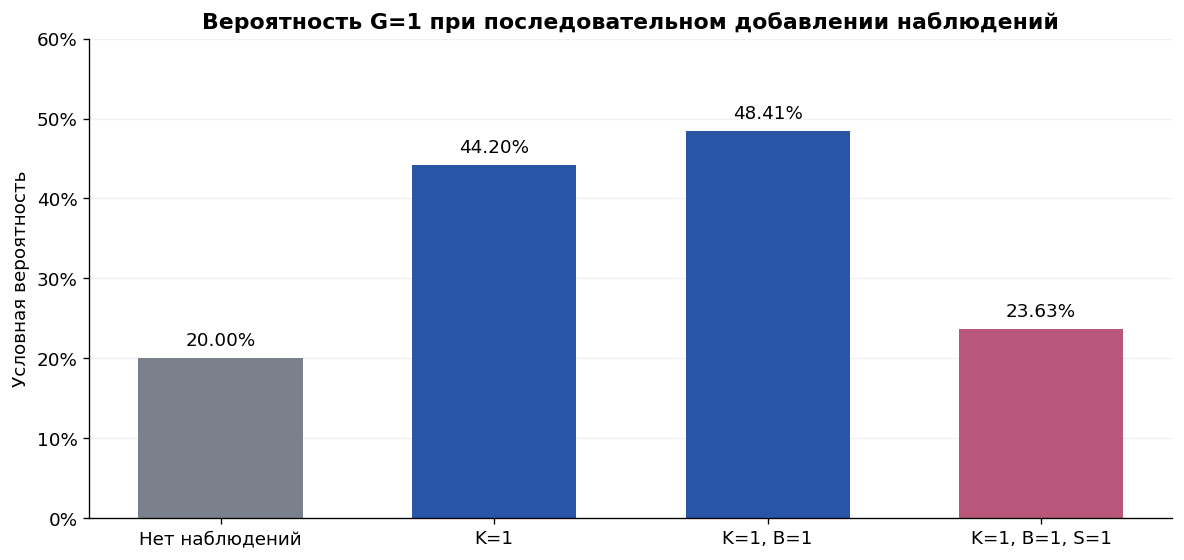

In [8]:
EVIDENCE_STEPS = [
    ("Нет наблюдений", {}),
    ("K=1", {"K": 1}),
    ("K=1, B=1", {"K": 1, "B": 1}),
    ("K=1, B=1, S=1", {"K": 1, "B": 1, "S": 1}),
]

evidence_results = pd.DataFrame([
    {"Наблюдения": name, "P(G=1 | evidence)": probability(reference_inference, "G", evidence)}
    for name, evidence in EVIDENCE_STEPS
])
display(evidence_results.round(6))

fig, ax = plt.subplots(figsize=(10, 4.8))
values = evidence_results["P(G=1 | evidence)"].to_numpy()
bars = ax.bar(evidence_results["Наблюдения"], values,
              color=[COLORS["muted"], COLORS["main"], COLORS["main"], COLORS["accent"]],
              width=0.6)
ax.bar_label(bars, labels=[f"{value:.2%}" for value in values], padding=5)
ax.set(title="Вероятность G=1 при последовательном добавлении наблюдений",
       ylabel="Условная вероятность", ylim=(0, 0.60))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### Разбор графика

Сигнал `K=1` дает косвенную информацию о пропаже и увеличивает вероятность `G=1`.
Прямое наблюдение `B=1` уточняет ответ.
После появления `S=1` вероятность снижается, поскольку появляется альтернативное объяснение.

Новые наблюдения не обязаны монотонно повышать вероятность выбранного события.
Итог зависит от набора evidence, а не от порядка его добавления в точном выводе.

## 8. Условные независимости и explaining away

Для заданного графа выполняются

$$G\perp S, \qquad G\perp K\mid B.$$

При наблюдении общего результата `B` путь через коллайдер открывается.
Структура допускает зависимость `G` и `S` при известном `B`.
Направление и величина эффекта зависят от CPD.

,Пара узлов,Наблюдения,Есть активный путь
0,G и S,Нет,False
1,G и S,B,True
2,G и K,B,False


,Наблюдения,P(G=1)
0,B=1,0.484073
1,"B=1, S=0",0.957447
2,"B=1, S=1",0.236277


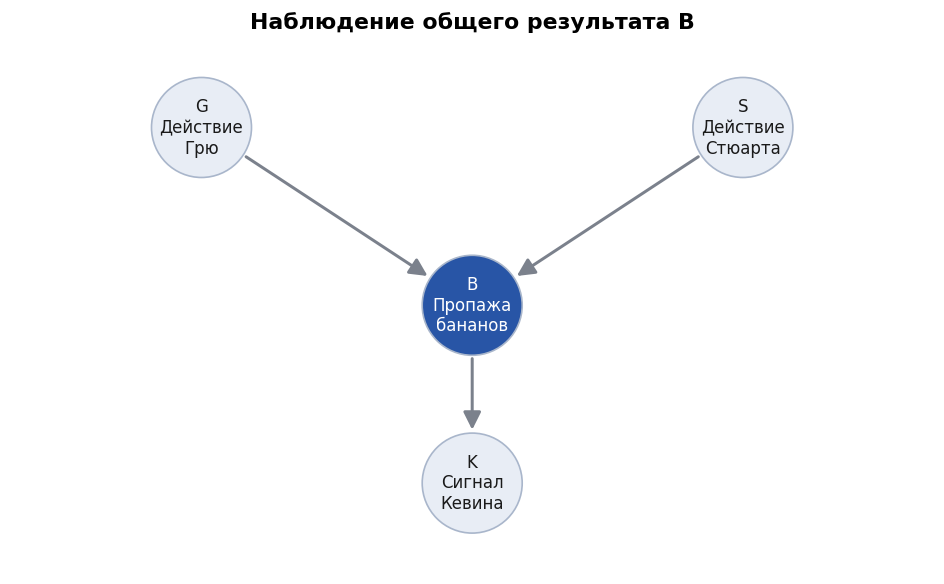

In [9]:
independence_checks = pd.DataFrame([
    {"Пара узлов": "G и S", "Наблюдения": "Нет",
     "Есть активный путь": reference_model.is_dconnected("G", "S")},
    {"Пара узлов": "G и S", "Наблюдения": "B",
     "Есть активный путь": reference_model.is_dconnected("G", "S", observed=["B"])},
    {"Пара узлов": "G и K", "Наблюдения": "B",
     "Есть активный путь": reference_model.is_dconnected("G", "K", observed=["B"])},
])
display(independence_checks)

explaining_away = pd.DataFrame([
    {"Наблюдения": "B=1", "P(G=1)": probability(reference_inference, "G", {"B": 1})},
    {"Наблюдения": "B=1, S=0", "P(G=1)": probability(reference_inference, "G", {"B": 1, "S": 0})},
    {"Наблюдения": "B=1, S=1", "P(G=1)": probability(reference_inference, "G", {"B": 1, "S": 1})},
])
display(explaining_away.round(6))

assert not reference_model.is_dconnected("G", "S")
assert reference_model.is_dconnected("G", "S", observed=["B"])
assert not reference_model.is_dconnected("G", "K", observed=["B"])
assert np.isclose(
    probability(reference_inference, "G", {"B": 1}),
    probability(reference_inference, "G", {"B": 1, "K": 1}),
)
draw_network(reference_model, observed=["B"], title="Наблюдение общего результата B")

### Что именно проверено

Граф гарантирует независимость `G` и `S` без наблюдений.
После фиксации `B=1` знание `S` меняет вероятность `G=1`.
При `B=1` дополнительный сигнал `K=1` уже не меняет ответ о `G`.

Проверка активных путей использует структуру графа.
Числовое совпадение отдельных условных вероятностей само по себе не доказывает
условную независимость для произвольных значений переменных.

## 9. Генерация наблюдений из известной модели

Перейдем от заданных параметров к данным. Сгенерируем две независимые выборки
из той же сети. Первая нужна для оценки CPD, вторая для оценки качества
восстановленного совместного распределения.

Используем ancestral sampling. Узлы обрабатываются в топологическом порядке,
и каждый узел генерируется при уже известных состояниях родителей.
Функция ниже предназначена для бинарных переменных с порядком состояний `[0, 1]`.

In [10]:
def sample_binary_network(
    model: DiscreteBayesianNetwork,
    n_samples: int,
    seed: int,
) -> pd.DataFrame:
    """Генерирует полные независимые наблюдения из бинарной сети."""
    if n_samples <= 0:
        raise ValueError("Размер выборки должен быть положительным.")
    rng = np.random.default_rng(seed)
    sampled = {}
    for node in nx.topological_sort(model):
        cpd = model.get_cpds(node)
        if any(cpd.state_names[var] != [0, 1] for var in cpd.variables):
            raise ValueError("Ожидаются бинарные состояния в порядке [0, 1].")
        parents = cpd.variables[1:]
        if parents:
            index = (1, *(sampled[parent] for parent in parents))
            success_probability = np.asarray(cpd.values)[index]
        else:
            success_probability = float(cpd.values[1])
        sampled[node] = (rng.random(n_samples) < success_probability).astype(int)
    return pd.DataFrame(sampled).loc[:, list(NODES)]


train_data = sample_binary_network(reference_model, N_TRAIN, seed=SEED)
test_data = sample_binary_network(reference_model, N_TEST, seed=SEED + 1)
assert not train_data.isna().any().any()
assert train_data.isin([0, 1]).all().all()
display(train_data.head())
print(f"Обучающих наблюдений: {len(train_data):,}")
print(f"Контрольных наблюдений: {len(test_data):,}")

Обучающих наблюдений: 5,000
Контрольных наблюдений: 2,000


,G,S,B,K
0,0,1,1,1
1,0,0,0,0
2,0,0,0,0
3,0,1,1,0
4,1,1,1,1


In [11]:
parent_support = (
    train_data.groupby(["G", "S"], observed=True)["B"]
    .agg(n="size", n_positive="sum", empirical_probability="mean")
    .reindex(pd.MultiIndex.from_product([[0, 1], [0, 1]], names=["G", "S"]))
)
display(parent_support)

n  n_positive  empirical_probability
G S                                         
0 0  2783          23               0.008264
  1  1192         958               0.803691
1 0   715         650               0.909091
  1   310         308               0.993548

### Проверка поддержки условных оценок

Для оценки `P(B | G,S)` важен размер каждой группы родителей, а не только общий размер таблицы.
В небольших выборках некоторые комбинации могут отсутствовать.
Даже при наличии группы редкое состояние дочернего узла может не встретиться.

Здесь механизм генерации полностью известен. Это позволяет сравнить оцененные CPD
с эталонными, чего обычно нельзя сделать на реальных данных.

## 10. Оценка параметров по данным

При фиксированной структуре для полных дискретных данных оценка максимального
правдоподобия равна условной частоте

$$\widehat P(X=x\mid U=u)=\frac{N(x,u)}{N(u)}.$$

Сравним MLE и оценку с априорным распределением BDeu.
В pgmpy 1.1.2 используем `DiscreteMLE` и `DiscreteBayesianEstimator`
из `pgmpy.parameter_estimator`. Параметры оценки передаются при создании estimator.

В BDeu параметр `equivalent_sample_size` распределяется по состояниям узла
и конфигурациям родителей. Это не то же самое, что добавление единицы в каждую ячейку.

In [12]:
def fit_network(
    data: pd.DataFrame,
    edges: Sequence[tuple[str, str]],
    method: str = "bdeu",
    equivalent_sample_size: float = EQUIVALENT_SAMPLE_SIZE,
) -> DiscreteBayesianNetwork:
    """Оценивает CPD новой сети, сохраняя все узлы и допустимые состояния."""
    if set(NODES) - set(data.columns):
        raise ValueError("В данных отсутствуют обязательные переменные.")
    if data.loc[:, list(NODES)].isna().any().any():
        raise ValueError("Перед оценкой нужно обработать пропуски.")
    if not data.loc[:, list(NODES)].isin([0, 1]).all().all():
        raise ValueError("Ожидаются бинарные значения 0 и 1.")

    model = DiscreteBayesianNetwork(edges)
    model.add_nodes_from(NODES)
    if method == "mle":
        estimator = DiscreteMLE(state_names=STATE_NAMES, n_jobs=1)
    elif method == "bdeu":
        if equivalent_sample_size <= 0:
            raise ValueError("equivalent_sample_size должен быть положительным.")
        estimator = DiscreteBayesianEstimator(
            state_names=STATE_NAMES, prior_type="BDeu",
            equivalent_sample_size=equivalent_sample_size, n_jobs=1,
        )
    elif method == "laplace":
        estimator = DiscreteBayesianEstimator(
            state_names=STATE_NAMES, prior_type="dirichlet", pseudo_counts=1, n_jobs=1,
        )
    else:
        raise ValueError(f"Неизвестный способ оценки: {method}")
    model.fit(data, estimator=estimator)
    assert model.check_model()
    return model


mle_model = fit_network(train_data, EDGES, method="mle")
bdeu_model = fit_network(train_data, EDGES, method="bdeu")

cpd_comparison = cpd_frame(reference_model, "B").loc[:, ["G", "S"]]
for name, model in {"Эталон": reference_model, "MLE": mle_model, "BDeu": bdeu_model}.items():
    cpd_comparison[name] = cpd_frame(model, "B")["P(B=1)"].to_numpy()
display(cpd_comparison.round(6))

,G,S,Эталон,MLE,BDeu
0,0,0,0.01,0.008264,0.008485
1,0,1,0.80,0.803691,0.803373
2,1,0,0.90,0.909091,0.908377
3,1,1,0.99,0.993548,0.991566


In [13]:
fitted_query_rows = []
for name, model in {"Эталон": reference_model, "MLE": mle_model, "BDeu": bdeu_model}.items():
    inference = VariableElimination(model)
    for query_name, target, evidence in QUERY_SPECS:
        fitted_query_rows.append({
            "Модель": name, "Запрос": query_name,
            "Вероятность": probability(inference, target, evidence),
        })

fitted_queries = pd.DataFrame(fitted_query_rows).pivot(
    index="Запрос", columns="Модель", values="Вероятность"
)
display(fitted_queries.round(6))

Модель,BDeu,MLE,Эталон
Запрос,,,
Диагностический вывод,0.493543,0.493600,0.484073
Конкурирующее объяснение,0.241759,0.241721,0.236277
Прогноз пропажи,0.933384,0.934462,0.927000


### Интерпретация оценок

Параметры, оцененные по конечной выборке, отличаются от эталона из-за случайности данных.
На достаточно наполненных группах MLE и BDeu обычно близки.
Сглаживание заметнее влияет на редкие конфигурации и небольшие выборки.

Разница между точным выводом и обучением принципиальна. Алгоритм вывода может точно
рассчитать условную вероятность в модели с неточно оцененными параметрами.

## 11. Нулевая частота и сглаживание

Рассмотрим отдельную малую выборку. Во всех десяти наблюдениях родители имеют
`G=0, S=0`, а событие `B=1` не встретилось.

Для этой наблюдаемой конфигурации MLE дает ноль.
При симметричном Dirichlet с единичными псевдосчетчиками posterior mean равен

$$\frac{0+1}{10+2}=\frac{1}{12}\approx0.0833.$$

Сглаживание отражает априорное допущение и не является доказательством существования события.

In [14]:
rare_data = pd.DataFrame(0, index=range(N_RARE), columns=list(NODES))
rare_models = {
    "MLE": fit_network(rare_data, EDGES, method="mle"),
    "Лаплас": fit_network(rare_data, EDGES, method="laplace"),
    "BDeu, ESS=5": fit_network(rare_data, EDGES, method="bdeu"),
}
rare_results = pd.Series({
    name: float(model.get_cpds("B").get_value(B=1, G=0, S=0))
    for name, model in rare_models.items()
}, name="P(B=1 | G=0, S=0)")
display(rare_results.to_frame())
assert np.isclose(rare_results["MLE"], 0.0)
assert np.isclose(rare_results["Лаплас"], 1 / 12)

,"P(B=1 | G=0, S=0)"
MLE,0.000000
Лаплас,0.083333
"BDeu, ESS=5",0.055556


В этом эксперименте сравнивается одна **наблюдаемая** комбинация родителей.
Для совсем ненаблюдавшихся комбинаций частотная оценка не определяется данными.
Библиотечное заполнение таких CPD нельзя трактовать как эмпирическое подтверждение.

Явный `state_names` сохраняет состояния, которые допустимы в задаче,
даже если они не встретились в малой обучающей выборке.

## 12. Удаление ребра и повторная оценка

Удалим `S → B`. Переменная `S` останется в сети, но станет изолированной.
Новая структура предполагает, что наблюдение `S` не влияет на вывод о `G` и `B`.

Сначала переоценим обе структуры на одних и тех же данных с одинаковым сглаживанием.
Простое удаление линии на рисунке не заменяет повторную оценку локальных распределений.

,Структура,"P(G=1 | B=1, S=1)"
0,Исходная,0.241759
1,Без S → B,0.494077


,G,P(B=0),P(B=1)
0,0,0.753048,0.246952
1,1,0.066423,0.933577


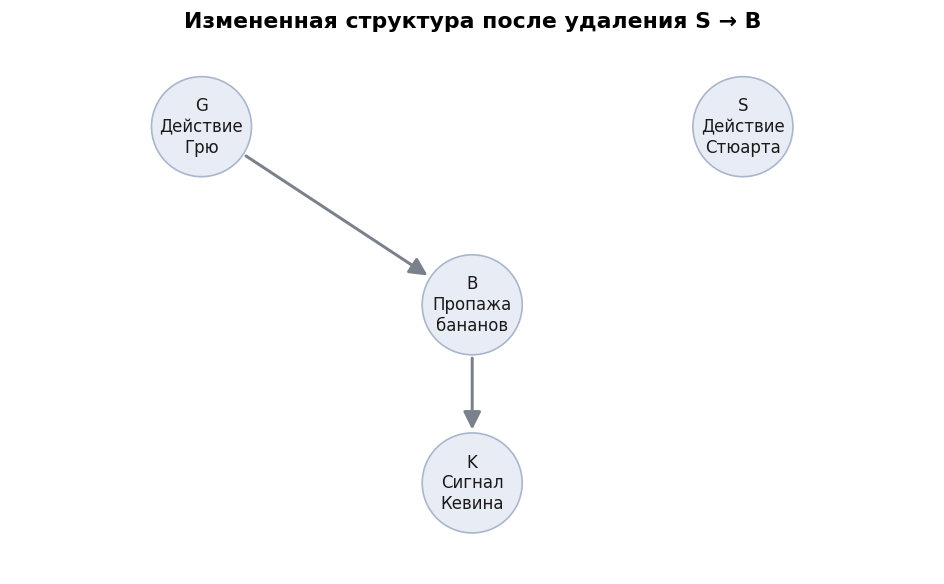

In [15]:
reduced_model = fit_network(train_data, REDUCED_EDGES, method="bdeu")
comparison_evidence = {"B": 1, "S": 1}
structure_results = pd.DataFrame([
    {"Структура": "Исходная", "P(G=1 | B=1, S=1)":
     probability(VariableElimination(bdeu_model), "G", comparison_evidence)},
    {"Структура": "Без S → B", "P(G=1 | B=1, S=1)":
     probability(VariableElimination(reduced_model), "G", comparison_evidence)},
])
display(structure_results.round(6))
display(cpd_frame(reduced_model, "B"))
draw_network(reduced_model, title="Измененная структура после удаления S → B")

### Аналитическое сравнение без ошибки конечной выборки

Чтобы воспроизвести числа презентации, отдельно построим измененную модель
с точным усреднением исходного распределения по `S`.

$$P_{\mathrm{reduced}}(B\mid G)=\sum_s P(S=s)P(B\mid G,S=s).$$

Это популяционный аналог повторной оценки, а не сохранение прежней CPD.
В реальных данных исходное совместное распределение обычно неизвестно.

In [16]:
def build_reduced_reference() -> DiscreteBayesianNetwork:
    """Точно переоценивает CPD B после удаления S → B в учебной модели."""
    model = DiscreteBayesianNetwork(REDUCED_EDGES)
    model.add_nodes_from(NODES)
    p_s = reference_model.get_cpds("S")
    cpd_b = reference_model.get_cpds("B")
    p_b = [
        sum(float(p_s.get_value(S=s)) * float(cpd_b.get_value(B=1, G=g, S=s))
            for s in (0, 1))
        for g in (0, 1)
    ]
    model.add_cpds(
        *(reference_model.get_cpds(node).copy() for node in ("G", "S", "K")),
        TabularCPD("B", 2, [[1 - value for value in p_b], p_b],
                   evidence=["G"], evidence_card=[2],
                   state_names={"B": [0, 1], "G": [0, 1]}),
    )
    assert model.check_model()
    return model


reduced_reference = build_reduced_reference()
reduced_reference_inference = VariableElimination(reduced_reference)
exact_structure_comparison = pd.Series({
    "Исходная модель": probability(reference_inference, "G", comparison_evidence),
    "Без S → B": probability(reduced_reference_inference, "G", comparison_evidence),
}, name="P(G=1 | B=1, S=1)")
display(exact_structure_comparison.to_frame())
np.testing.assert_allclose(exact_structure_comparison, [0.23627684964200474, 0.4840731070496084])
assert np.isclose(
    probability(reduced_reference_inference, "G", {"B": 1}),
    probability(reference_inference, "G", {"B": 1}),
)

,"P(G=1 | B=1, S=1)"
Исходная модель,0.236277
Без S → B,0.484073


### Интерпретация изменения структуры

После удаления ребра информация о `S` перестает объяснять результат `B` внутри модели.
Поэтому она больше не снижает вероятность `G=1` при известном `B=1`.

Удаление ребра не обязано менять каждый запрос. В данном аналитическом эксперименте
`P(G=1 | B=1)` сохраняется, хотя запрос с дополнительным `S=1` меняется.
Изменение модельной гипотезы не означает изменения механизма, который создал данные.

## 13. Качество совместного распределения

Для вероятностной сети полезно оценивать вероятность полных наблюдений.
На независимой контрольной выборке вычислим среднюю отрицательную логарифмическую
вероятность

$$\mathrm{NLL}=-\frac{1}{n}\sum_{i=1}^n\log P(x_i).$$

Меньшее значение лучше. Используем натуральный логарифм, единица измерения составляет нат на наблюдение.

Поскольку распределение генератора известно, дополнительно можно точно вычислить
$D_{KL}(P_{\mathrm{true}}\Vert P_{\mathrm{model}})$ по 16 состояниям.
Этот критерий на реальных данных обычно недоступен.

In [17]:
def evaluate_distribution(
    model: DiscreteBayesianNetwork,
    data: pd.DataFrame,
    reference_joint: pd.DataFrame,
) -> dict[str, float]:
    """Оценивает NLL на наблюдениях и точную KL от известного генератора."""
    model_joint = enumerate_joint(model)
    index_columns = list(NODES)
    probabilities = model_joint.set_index(index_columns)["probability"]
    observation_index = pd.MultiIndex.from_frame(data.loc[:, index_columns])
    likelihood = probabilities.reindex(observation_index).to_numpy()
    if np.isnan(likelihood).any():
        raise ValueError("В контрольной выборке обнаружены неизвестные состояния.")
    nll = float(-np.log(likelihood).mean()) if (likelihood > 0).all() else np.inf

    reference_p = reference_joint.set_index(index_columns)["probability"]
    model_p = probabilities.reindex(reference_p.index)
    positive = reference_p.gt(0)
    if model_p.loc[positive].eq(0).any():
        kl = np.inf
    else:
        kl = float((reference_p.loc[positive] *
                    np.log(reference_p.loc[positive] / model_p.loc[positive])).sum())
    return {"NLL на test": nll, "KL от эталона": kl}


quality_results = pd.DataFrame({
    name: evaluate_distribution(model, test_data, joint)
    for name, model in {
        "Эталон": reference_model,
        "Исходная, MLE": mle_model,
        "Исходная, BDeu": bdeu_model,
        "Без S → B, BDeu": reduced_model,
    }.items()
}).T
display(quality_results.round(6))

,NLL на test,KL от эталона
Эталон,1.622796,0.000000
"Исходная, MLE",1.625307,0.000848
"Исходная, BDeu",1.625193,0.000822
"Без S → B, BDeu",1.930063,0.299893


### Разбор результата

У эталона KL равна нулю. Значения для обученных моделей отражают ошибку оценки параметров
и, в измененном графе, ограничение структуры.
На отдельной конечной контрольной выборке эталон не обязан получать минимальную эмпирическую NLL.
В среднем по данным из генератора минимум ожидаемой NLL достигается его истинным распределением.

Если модель присвоила нулевую вероятность наблюдаемому событию, NLL становится бесконечной.
В этом блокноте такие вероятности не подменяются скрытым обрезанием до малого положительного числа.

## 14. Чувствительность к силе априорного распределения

Повторим оценку на малой подвыборке из 60 наблюдений и изменим `equivalent_sample_size`.
Граф и данные остаются одинаковыми. Этот эксперимент показывает чувствительность ответа
к одному предположению о параметрах.

Ни одно значение ESS не объявляется универсально лучшим.

,ESS,"P(G=1 | B=1, S=1)"
0,0.1,0.238716
1,1.0,0.239317
2,5.0,0.243683
3,20.0,0.268129
4,100.0,0.360769


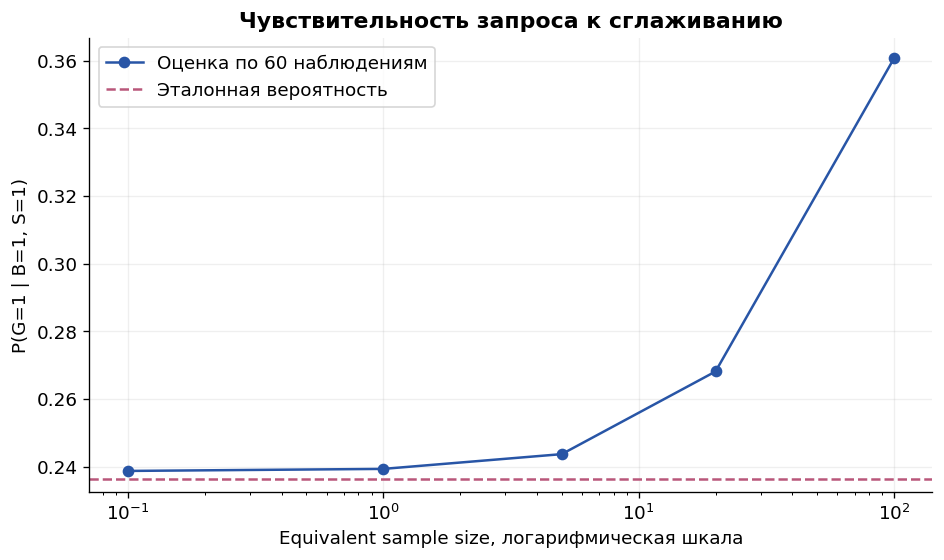

In [18]:
sensitivity_data = train_data.iloc[:N_SENSITIVITY].copy()
sensitivity_rows = []
for ess in ESS_VALUES:
    model = fit_network(sensitivity_data, EDGES, method="bdeu", equivalent_sample_size=ess)
    sensitivity_rows.append({
        "ESS": ess,
        "P(G=1 | B=1, S=1)": probability(VariableElimination(model), "G", comparison_evidence),
    })
sensitivity_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_results.round(6))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(sensitivity_results["ESS"], sensitivity_results["P(G=1 | B=1, S=1)"],
        marker="o", color=COLORS["main"], label="Оценка по 60 наблюдениям")
ax.axhline(probability(reference_inference, "G", comparison_evidence),
           color=COLORS["accent"], linestyle="--", label="Эталонная вероятность")
ax.set(xscale="log", xlabel="Equivalent sample size, логарифмическая шкала",
       ylabel="P(G=1 | B=1, S=1)", title="Чувствительность запроса к сглаживанию")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

## 15. Наблюдение и вмешательство

Этот раздел требует дополнительной **причинной** интерпретации графа.
Предположим, что стрелки описывают механизмы, скрытых общих причин нет,
а вмешательство в `B` не меняет остальные механизмы напрямую.

Наблюдение `B=1` дает информацию о возможных объяснениях.
Вмешательство $do(B=1)$ принудительно задает `B` и удаляет входящие в него стрелки.
Оно не увеличивает вероятность исходного события `G`.

In [19]:
intervened_model = DiscreteBayesianNetwork([("B", "K")])
intervened_model.add_nodes_from(NODES)
intervened_model.add_cpds(
    *(reference_model.get_cpds(node).copy() for node in ("G", "S", "K")),
    TabularCPD("B", 2, [[0.0], [1.0]], state_names={"B": [0, 1]}),
)
assert intervened_model.check_model()
intervened_inference = VariableElimination(intervened_model)
causal_comparison = pd.Series({
    "P(G=1)": probability(reference_inference, "G"),
    "P(G=1 | B=1)": probability(reference_inference, "G", {"B": 1}),
    "P(G=1 | do(B=1))": probability(intervened_inference, "G"),
}, name="Вероятность")
display(causal_comparison.to_frame())
assert np.isclose(causal_comparison.iloc[0], causal_comparison.iloc[2])

,Вероятность
P(G=1),0.200000
P(G=1 | B=1),0.484073
P(G=1 | do(B=1)),0.200000


### Ограничение причинного вывода

`query(..., evidence={...})` выполняет условный вероятностный запрос.
Он не превращает наблюдение во вмешательство.
В последней ячейке интервенция реализована через явное изменение причинной модели.

Данный расчет не доказывает, что построенная по наблюдениям сеть является причинной.
Для реальной задачи требуется обоснование графа и допущений о механизмах.

## 16. Самостоятельные эксперименты

1. Измените одну из вероятностей в `build_reference_model`. До запуска предскажите,
   как изменится один выбранный запрос, затем проверьте ответ.
2. Сравните `P(G=1 | K=1)` и `P(G=1 | K=1, S=1)`.
   Объясните влияние наблюдаемого потомка коллайдера.
3. Уменьшите размер обучающей выборки. Посмотрите поддержку комбинаций родителей
   и сравните MLE со сглаживанием.
4. Выберите другое ребро для структурного эксперимента.
   Сохраните все переменные, переоцените обе модели на одинаковых данных и сравните содержательный запрос.
5. Предложите свою предметную область и три вопроса к данным.
   Для ЛР №4 нужен собственный открытый датасет и обоснованный граф.

При объяснении результата указывайте целевую переменную, evidence,
вероятность до наблюдений, вероятность после наблюдений и ограничения интерпретации.

## 17. Основные выводы

- Граф и CPD вместе задают совместное распределение.
- Для точного вывода неизвестные переменные суммируются, а не заменяются нулями.
- Наблюдение коллайдера или его потомка может создавать зависимость между объяснениями.
- Оценка параметров и вероятностный вывод решают разные задачи.
- Сглаживание и структура влияют на ответы, особенно при малом объеме данных.
- После изменения графа локальные распределения нужно согласовать с новой структурой.
- Причинные вопросы требуют дополнительных допущений.

### Материалы

- [MIT 6.034. Probability and Bayes nets](https://ocw.mit.edu/courses/6-034-artificial-intelligence-fall-2010/resources/mit6_034f10_tutor06/)
- [Курс Евгения Соколова. Байесовские методы](https://github.com/esokolov/ml-course-hse/blob/master/2025-spring/seminars/sem16-bayes.tex)
- [CMU 10-708. Bayesian Networks](https://www.cs.cmu.edu/~epxing/Class/10708-19/notes/lecture-02/)
- [CMU 10-708. Exact Inference](https://www.cs.cmu.edu/~epxing/Class/10708-19/notes/lecture-04/)
- [pgmpy. DiscreteBayesianNetwork](https://pgmpy.org/api/generated/models/pgmpy.models.DiscreteBayesianNetwork.html)
- [pgmpy. DiscreteBayesianEstimator](https://github.com/pgmpy/pgmpy/blob/v1.1.2/pgmpy/parameter_estimator/discrete_bayesian.py)
- [Pearl, Glymour, Jewell. Causal Inference in Statistics](https://bayes.cs.ucla.edu/PRIMER/)
- [Лабораторная работа №4](https://github.com/lesopylka/ml_course_mai/blob/main/bayesian/lab04.pdf)